<a href="https://colab.research.google.com/github/zijierongjay/MSSP607/blob/main/Modules/Week_8/Untitled10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ID: zijierongjay

1.

In [3]:
from google.colab import userdata
import os
import subprocess

os.chdir('/content')

github_token = userdata.get('Git_Key')

owner = 'zijierongjay'
repository = 'MSSP607'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

subprocess.run(
    ['git', 'clone', clone_url],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

os.chdir(repository)

print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607


In [4]:
os.listdir('Modules/Week_8')

['.gitkeep', 'InternetSales.csv']

In [ ]:
2.

In [5]:
import pandas as pd

internet_sales = pd.read_csv(
    'Modules/Week_8/InternetSales.csv',
    encoding='latin1'
)

internet_sales.head()

/tmp/ipykernel_1958/1713420002.py:3: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  internet_sales = pd.read_csv(


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [6]:
internet_sales.columns

Index(['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode',
       'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title',
       'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate',
       'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome',
       'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation',
       'SpanishEducation', 'FrenchEducation', 'EnglishOccupation',
       'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag',
       'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone',
       'DateFirstPurchase', 'CommuteDistance', 'ProductKey',
       'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey',
       'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey',
       'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber',
       'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct',
       'DiscountAmount', 'ProductStandardCost', 'TotalProductCost',
       'SalesAmo

In [7]:
internet_sales['OrderDate'] = pd.to_datetime(
    internet_sales['OrderDate']
)

In [8]:
internet_sales = internet_sales.assign(
    orderyear = internet_sales['OrderDate'].dt.year
)

internet_sales = internet_sales.assign(
    orderquarter = internet_sales['OrderDate'].dt.quarter
)

internet_sales = internet_sales.assign(
    ordermonth = internet_sales['OrderDate'].dt.month
)

internet_sales = internet_sales.assign(
    orderday = internet_sales['OrderDate'].dt.day
)

internet_sales.head()

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate,orderyear,orderquarter,ordermonth,orderday
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,84.9998,NaN,NaN,2011-01-19,1/31/2011,1/26/2011,2011,1,1,19
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,57.9998,NaN,NaN,2013-01-18,1/30/2013,1/25/2013,2013,1,1,18
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,0.5495,NaN,NaN,2013-01-18,1/30/2013,1/25/2013,2013,1,1,18
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,59.6018,NaN,NaN,2013-05-03,5/15/2013,5/10/2013,2013,2,5,3
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,0.7248,NaN,NaN,2013-05-03,5/15/2013,5/10/2013,2013,2,5,3


In [9]:
internet_sales[
    ['OrderDate', 'orderyear', 'orderquarter', 'ordermonth', 'orderday']
].head()

,OrderDate,orderyear,orderquarter,ordermonth,orderday
0,2011-01-19,2011,1,1,19
1,2013-01-18,2013,1,1,18
2,2013-01-18,2013,1,1,18
3,2013-05-03,2013,2,5,3
4,2013-05-03,2013,2,5,3


In [10]:
yearly_sales = internet_sales.groupby(
    ['orderyear']
).agg(
    {'SalesAmount': 'sum'}
)

yearly_sales

,SalesAmount
orderyear,
2010,4.342104e+04
2011,7.075526e+06
2012,5.842485e+06
2013,1.635155e+07
2014,4.569472e+04


In [11]:
from sklearn.linear_model import LinearRegression

In [12]:
forecast_data = yearly_sales.reset_index()

forecast_data

,orderyear,SalesAmount
0,2010,4.342104e+04
1,2011,7.075526e+06
2,2012,5.842485e+06
3,2013,1.635155e+07
4,2014,4.569472e+04


In [13]:
X = forecast_data[['orderyear']]
y = forecast_data['SalesAmount']

In [14]:
model = LinearRegression()

model.fit(X, y)

LinearRegression()

In [15]:
future_years = pd.DataFrame({
    'orderyear': [2015, 2016, 2017, 2018, 2019]
})

future_years['ForecastedSales'] = model.predict(
    future_years[['orderyear']]
)

future_years

,orderyear,ForecastedSales
0,2015,8.655907e+06
1,2016,9.583964e+06
2,2017,1.051202e+07
3,2018,1.144008e+07
4,2019,1.236814e+07


In [16]:
product_sales = internet_sales.groupby(
    ['EnglishProductName']
).agg(
    {'SalesAmount': 'sum'}
).sort_values(
    by='SalesAmount',
    ascending=False
)

product_sales.head(10)

,SalesAmount
EnglishProductName,
"Mountain-200 Black, 46",1.373470e+06
"Mountain-200 Black, 42",1.363142e+06
"Mountain-200 Silver, 38",1.339463e+06
"Mountain-200 Silver, 46",1.301100e+06
"Mountain-200 Black, 38",1.294866e+06
"Mountain-200 Silver, 42",1.257435e+06
"Road-150 Red, 48",1.205877e+06
"Road-150 Red, 62",1.202299e+06
"Road-150 Red, 52",1.080638e+06


3. Based on the summary statistics, Mountain-200 Black, 46 generated the highest total sales, with approximately $1.37 million in sales.

In [17]:
internet_sales.groupby('orderyear')['ordermonth'].nunique()

,ordermonth
orderyear,
2010,1
2011,12
2012,12
2013,12
2014,1


In [18]:
complete_sales = yearly_sales.loc[2011:2013].reset_index()

complete_sales

,orderyear,SalesAmount
0,2011,7.075526e+06
1,2012,5.842485e+06
2,2013,1.635155e+07


In [19]:
X = complete_sales[['orderyear']]
y = complete_sales['SalesAmount']

model = LinearRegression()

model.fit(X, y)

LinearRegression()

In [20]:
future_years = pd.DataFrame({
    'orderyear': [2014, 2015, 2016, 2017, 2018]
})

future_years['ForecastedSales'] = model.predict(
    future_years[['orderyear']]
)

future_years

,orderyear,ForecastedSales
0,2014,1.903254e+07
1,2015,2.367056e+07
2,2016,2.830857e+07
3,2017,3.294658e+07
4,2018,3.758459e+07


4.

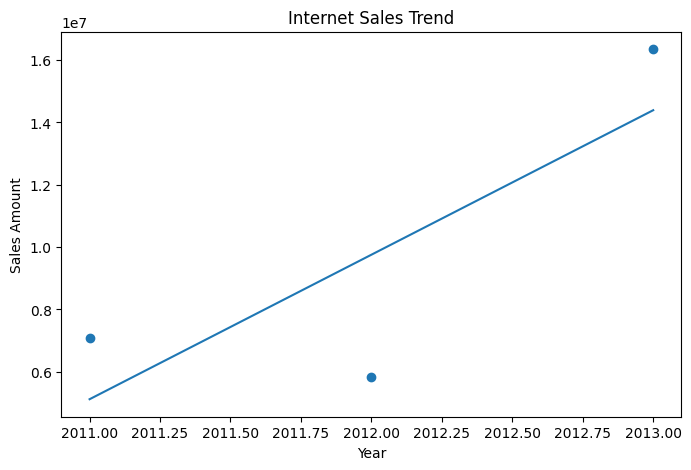

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    complete_sales['orderyear'],
    complete_sales['SalesAmount']
)

plt.plot(
    complete_sales['orderyear'],
    model.predict(complete_sales[['orderyear']])
)

plt.title('Internet Sales Trend')
plt.xlabel('Year')
plt.ylabel('Sales Amount')

plt.show()

In [23]:
future_years = pd.DataFrame({
    'orderyear': [2014, 2015, 2016, 2017, 2018]
})

future_years['ForecastedSales'] = model.predict(
    future_years[['orderyear']]
)

future_years

,orderyear,ForecastedSales
0,2014,1.903254e+07
1,2015,2.367056e+07
2,2016,2.830857e+07
3,2017,3.294658e+07
4,2018,3.758459e+07


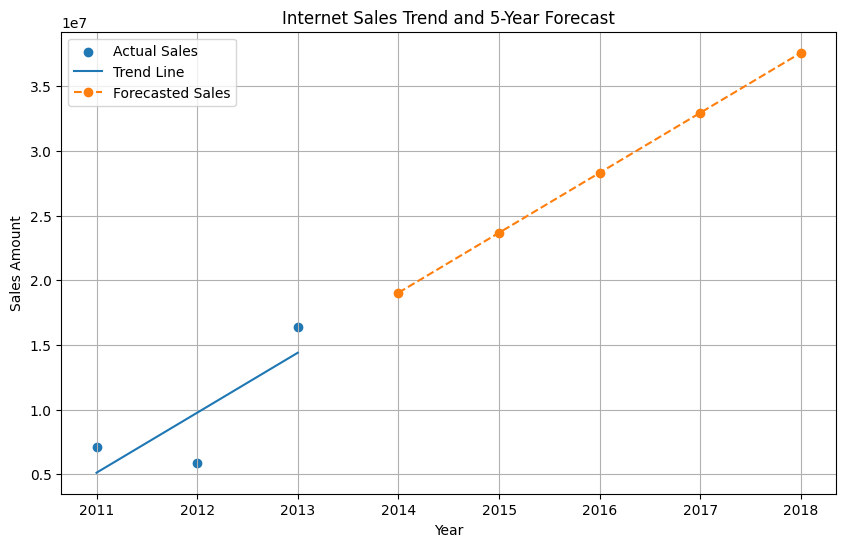

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    complete_sales['orderyear'],
    complete_sales['SalesAmount'],
    label='Actual Sales'
)

plt.plot(
    complete_sales['orderyear'],
    model.predict(complete_sales[['orderyear']]),
    label='Trend Line'
)

plt.plot(
    future_years['orderyear'],
    future_years['ForecastedSales'],
    marker='o',
    linestyle='--',
    label='Forecasted Sales'
)

plt.title('Internet Sales Trend and 5-Year Forecast')
plt.xlabel('Year')
plt.ylabel('Sales Amount')
plt.legend()
plt.grid(True)

plt.show()

In [26]:
from google.colab import files

files.download(
    '/content/MSSP607/Modules/Week_8/InternetSales.csv'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
future_years.to_csv(
    'InternetSales_5Year_Forecast.csv',
    index=False
)

files.download('InternetSales_5Year_Forecast.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>